# 5. Build a 3D scene, then interrogate it

**Question:** How do we place a flight path and sensors above a terrain surface?
**Objectives:** compose surface and point layers, enforce units, vary the camera, and understand
occlusion. **Time:** 30 minutes. **Prerequisite:** Chapter 4.

The fictional drone flies 140 metres above an analytic terrain surface. The scene is a spatial
model, not a flight-planning product. Local x, y, and z all use metres. Base R renders a fixed
view; the companion [interactive gallery](https://jltobias.github.io/JupyterLite-R/gallery/) lets
you rotate the same R-generated geometry. No basemap, token, or external elevation data is needed.
[Open in Lab](https://jltobias.github.io/JupyterLite-R/lite/lab/index.html?path=05-three-dimensional-scenes.ipynb)

In [1]:
# Project: JupyterLite-R | Chapter 05 | Purpose: layered synthetic 3D scene.
# Author: project contributors with Codex | Contact: repository Issues.
# Created/updated: 2026-11-16 | Inputs: equations | Outputs: scene and clearance audit.
# Dependencies: base R graphics. Change log: initial lesson.
terrain <- function(x, y) 100 + 850 * exp(-((x + 700)^2 + (y - 400)^2) / 2400000) +
  550 * exp(-((x - 1300)^2 + (y + 1000)^2) / 1100000)
x <- y <- seq(-3000, 3000, length.out = 51)
z <- outer(x, y, terrain)
flight <- data.frame(t = seq(0, 1, length.out = 100))
flight$x <- -2300 + 4600 * flight$t
flight$y <- 1300 * sin(2 * pi * flight$t)
flight$ground <- terrain(flight$x, flight$y)
flight$altitude <- flight$ground + 140
stopifnot(all(abs(flight$altitude - flight$ground - 140) < 1e-8))
head(flight)

           t         x        y   ground altitude
1 0.00000000 -2300.000   0.0000 373.6662 513.6662
2 0.01010101 -2253.535  82.4511 398.1552 538.1552
3 0.02020202 -2207.071 164.5702 422.3988 562.3988
4 0.03030303 -2160.606 246.0266 446.0077 586.0077
5 0.04040404 -2114.141 326.4924 468.6118 608.6118
6 0.05050505 -2067.677 405.6435 489.8801 629.8801


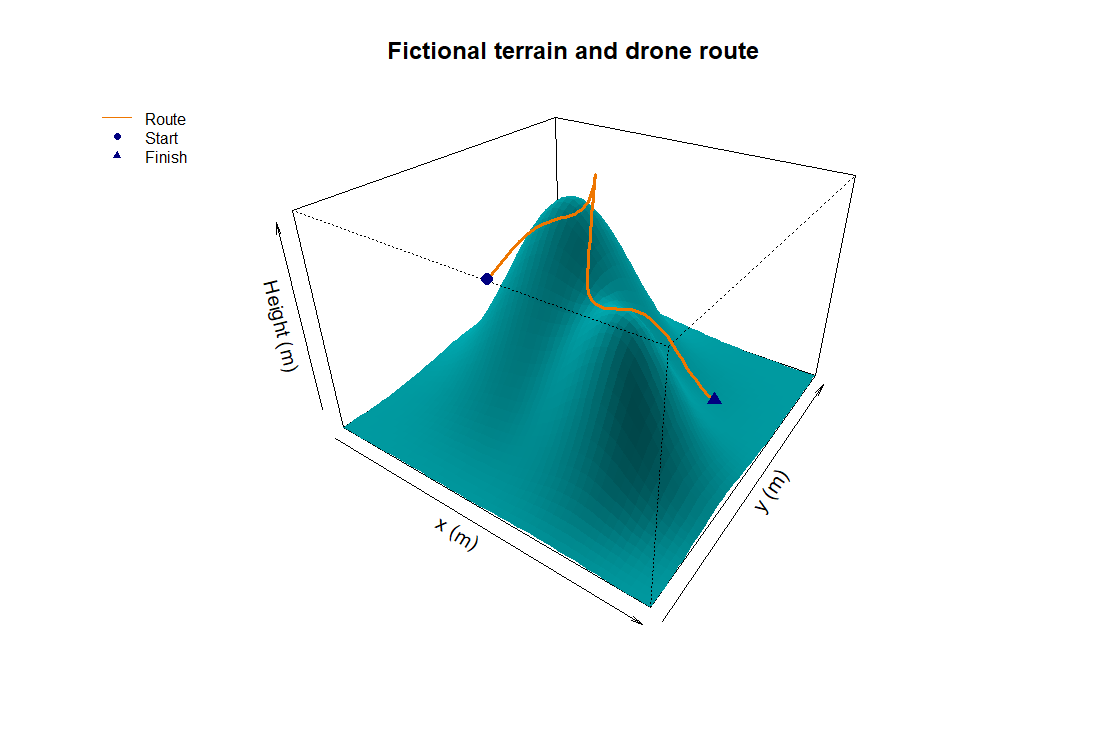

In [2]:
view <- persp(x, y, z, theta = 35, phi = 30, expand = .65,
              zlim = range(c(z, flight$altitude)), col = "turquoise3", border = NA,
              shade = .35, xlab = "x (m)", ylab = "y (m)", zlab = "Height (m)",
              main = "Fictional terrain and drone route")
route_xy <- trans3d(flight$x, flight$y, flight$altitude, view)
lines(route_xy, col = "darkorange2", lwd = 3)
points(trans3d(flight$x[c(1,100)], flight$y[c(1,100)], flight$altitude[c(1,100)], view),
       pch = c(16,17), col = "navy", cex = 1.3)
legend("topleft", c("Route", "Start", "Finish"), col = c("darkorange2", "navy", "navy"),
       lty = c(1,NA,NA), pch = c(NA,16,17), bty = "n", cex = .8)

`trans3d()` projects 3D coordinates using the camera matrix returned by `persp()`. It does not
perform hidden-surface removal for the added route: a line can appear above a ridge that should
hide it. The interactive WebGL scene uses depth buffering. Both displays need a numeric audit.

In [3]:
horizontal_step <- sqrt(diff(flight$x)^2 + diff(flight$y)^2)
spatial_step <- sqrt(horizontal_step^2 + diff(flight$altitude)^2)
audit <- data.frame(horizontal_route_m = sum(horizontal_step),
                    three_dimensional_route_m = sum(spatial_step),
                    minimum_clearance_m = min(flight$altitude - flight$ground))
stopifnot(audit$three_dimensional_route_m >= audit$horizontal_route_m)
print(audit)

  horizontal_route_m three_dimensional_route_m minimum_clearance_m
1           7191.923                  7348.268                 140


## Practice and check
1. Set constant altitude at 700 metres; calculate how many samples intersect terrain.
2. Compare cameras at 20 and 70 degrees elevation. Which hides more of the route?
3. Increase the number of route samples and assess convergence of its approximate length.
**Checkpoint:** clearance is exactly 140 m at sampled points. That is not proof of clearance
between samples for a real aircraft. Vertical exaggeration and perspective can mislead judgment.

## Sources
[R trans3d](https://stat.ethz.ch/R-manual/R-devel/library/grDevices/html/trans3d.html);
[Plotly.js surface documentation](https://plotly.com/javascript/3d-surface-plots/).
All terrain and flight coordinates are generated by the original code above.